# Logistic Regression and Evaluation — Exercise

**Dataset:** Swiss avalanche accident records; fatal = 1 if at least one person died.

Read [logistic_regression_evaluation_concept.ipynb](logistic_regression_evaluation_concept.ipynb) first. Run cells from top to bottom. Data preparation and plotting code are provided. Replace each `None` marked with a `# TODO` comment with the expression requested above the cell. These cells are incomplete until you fill the gap. Answer interpretation questions in one or two sentences. Check your work with [logistic_regression_evaluation_solution.ipynb](logistic_regression_evaluation_solution.ipynb).

## Libraries and settings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, RocCurveDisplay

## 1. Calculate a probability

For score 1, replace the gap with `1 / (1 + np.exp(-score))`. Which label follows at threshold 0.5?

Bei einem Score von 1 wird der Abstand durch `1 / (1 + np.exp(-score))` ersetzt. Welches Label folgt bei einem Schwellenwert von 0,5?

In [2]:
score = 1
# TODO: Replace None with the expression requested above.
p = 1 / (1 + np.exp(-score))
print('Probability:', round(p, 3))
print('Class at threshold 0.5:', int(p >= 0.5))

Probability: 0.731
Class at threshold 0.5: 1


**Answer**

Die Wahrscheinlichkeit für `score=1` liegt bei 73%, 0.5 legt den Schwellenwert fest. Wenn probability p >= 0.5 dann Label 1.

## 2. Load and split accident records

Preparation is provided. How is a positive case defined? At what time is the input available?

Es werden Vorbereitungen getroffen. Wie wird ein positiver Fall definiert? Ab wann stehen die Daten zur Verfügung?

In [3]:
aval = pd.read_csv('../00_Data/avalanche_accidents_switzerland.csv')
aval[['fully_buried', 'fatal']].head()

,fully_buried,fatal
0,0.0,0
1,1.0,1
2,1.0,0
3,1.0,1
4,1.0,1


In [4]:
aval = aval[aval['hydrological_year'] >= '2000/01'].copy() # Behalte in aval nur die Daten ab dem hydrologischen Jahr 2000/01 und speichere das Ergebnis als unabhängige Kopie wieder in aval.
aval = aval.dropna(subset=['fully_buried', 'fatal'])
X = aval[['fully_buried']]
y = aval['fatal']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print('Accidents:', len(aval), 'Share fatal:', round(y.mean(), 3))
print(X_train.head())

Accidents: 2876 Share fatal: 0.132
      fully_buried
2203           0.0
2338           0.0
1636           0.0
3625           0.0
2566           0.0


**Answer**

- The data contain 2876 recorded accidents since 2000/01; 13.2% of them were fatal.
- With `stratify=y`, training (2300 accidents) and test (576 accidents) both keep this 13.2% share. The test set contains 76 fatal accidents.

## 3. Train and see the sigmoid

Replace the gap with `LogisticRegression()`. Does more burial correspond to higher predicted probability?

Entspricht eine höhere Bestattungsrate einer höheren prognostizierten Wahrscheinlichkeit?

Intercept: [-3.0961586] Slope: [[2.25669197]]


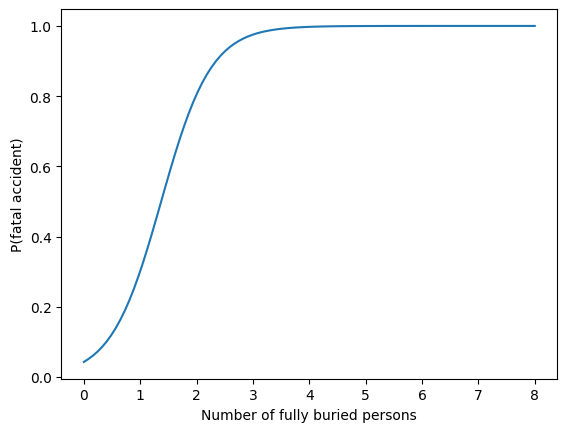

In [5]:
# TODO: Replace None with the expression requested above.
model = LogisticRegression()
model.fit(X_train, y_train)
print('Intercept:', model.intercept_, 'Slope:', model.coef_)
grid = pd.DataFrame({'fully_buried': np.linspace(0, 8, 100)})
plt.plot(grid['fully_buried'], model.predict_proba(grid)[:, 1]) # [:, 1] wählt aus einem zweidimensionalen Array alle Zeilen, aber nur die Spalte mit dem Index 1 aus.
plt.xlabel('Number of fully buried persons')
plt.ylabel('P(fatal accident)')
plt.show()
probability = model.predict_proba(X_test)[:, 1]

**Answer** Ja. Die Steigung ist positiv (2,26), daher steigt die Kurve mit der Anzahl der vollständig verschütteten Personen an.

- Achsenabschnitt −3,10: Wenn niemand vollständig verschüttet ist, gilt p = 1 / (1 + e³,¹⁰) ≈ 0,043.
- Jede weitere vollständig verschüttete Person erhöht den Wert um 2,26. Dadurch vervielfacht sich die Wahrscheinlichkeit eines tödlichen Ausgangs mit e².²⁶ ≈ 9,6.
- Vorhergesagte Wahrscheinlichkeiten: 0 verschüttete Personen → 0,043; 1 verschüttete Person → 0,302; 2 verschüttete Personen → 0,805; 3 verschüttete Personen → 0,975.
- Die Kurve steigt zwischen 1 und 2 verschütteten Personen steil an und flacht ab 3 verschütteten Personen in der Nähe von 1 ab.
- Hierbei handelt es sich um einen Zusammenhang innerhalb der erfassten Unfälle, nicht um einen kausalen Effekt.

## 4. Compute precision and recall by hand

Use the counts TN=75, FP=22, FN=24, TP=50. Replace the gap with `TP / (TP + FN)`. Explain precision versus recall.

In [6]:
TN, FP, FN, TP = 75, 22, 24, 50
precision = TP / (TP + FP)
# TODO: Replace None with the expression requested above.
recall = TP / (TP + FN)
print('Precision:', round(precision, 3))
print('Recall:', round(recall, 3))
print('FPR:', round(FP / (FP + TN), 3))

Precision: 0.694
Recall: 0.676
FPR: 0.227


**Answer**

- Precision: Es von den 72 positiven Meldungen sind 50 korrekt, somit Anteil der tatsächlich positiven Fälle unter allen als positiv vorhergesagten Fällen mit 69.4%
- Recall: Insgesamt gab es 74 positive Fälle, davon wurden 24 nicht dektektiert, somit Anteil der tatsächlich positiven Fälle hier 67.7%, die das Modell erkennt.

## 5. Evaluate the model

The evaluation is provided. Read the matrix rows and columns, and compare accuracy with the always-negative baseline. Why is recall also needed?

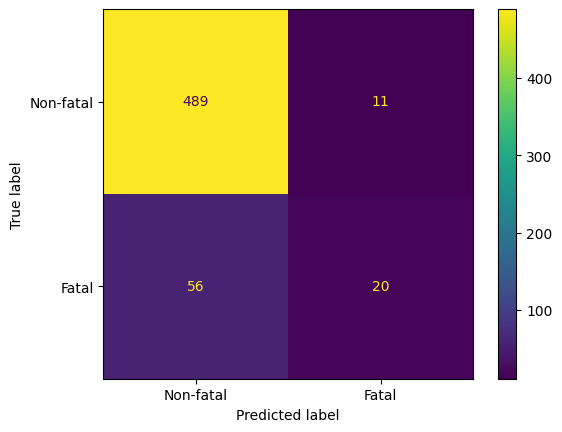

Accuracy: 0.884
Precision: 0.645
Recall: 0.263
F1: 0.374
Always-negative accuracy: 0.868


In [11]:
predicted = (probability >= 0.5).astype(int)  # probability = [0.2, 0.7, 0.4, 0.9] --> wandlet sie um unter Betrachtung des Schwellenwerts von 0.5 --> predicted = [0, 1, 0, 1]
cm = confusion_matrix(y_test, predicted, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=['Non-fatal', 'Fatal']).plot()
plt.show()
print('Accuracy:', round(accuracy_score(y_test, predicted), 3))
print('Precision:', round(precision_score(y_test, predicted, zero_division=0), 3))
print('Recall:', round(recall_score(y_test, predicted), 3))
print('F1:', round(f1_score(y_test, predicted), 3))
print('Always-negative accuracy:', round(1 - y_test.mean(), 3))

**Answer**

- Diese Verteilung spiegelt unausgeglichene Klassen wieder

- Bei einem Schwellenwert von 0,5 lautet die Testmatrix: TN = 489, FP = 11, FN = 56, TP = 20.
- Da p(1 verschüttet) = 0,302 und p(2 verschüttet) = 0,805 ist, bedeutet ein Schwellenwert von 0,5: „tödlich“ wird vorhergesagt, wenn zwei oder mehr Personen vollständig verschüttet sind.
- **Genauigkeit** = (489 + 20) / 576 = 0,884.
- **Immer-negativ-Basislinie:** Die Vorhersage „nicht tödlich“ für jeden Unfall ist bei den 500 nicht tödlichen Fällen richtig: 500 / 576 = 0,868. Das Modell ist nur um 0,016 besser.
- **Präzision** = 20 / 31 = 0,645: Etwa zwei Drittel der tödlichen Alarme sind korrekt.
- **Recall** = 20 / 76 = 0,263: Nur etwa jeder vierte tödliche Unfall wird erkannt. Bei 43 der 56 übersehenen Fälle war genau eine Person vollständig verschüttet.
- **F1** = 0,374, niedrig, da der Recall niedrig ist.
- Die Genauigkeit verschleiert diese Auslassungen, da 87 % der Unfälle ohnehin nicht tödlich sind. Der Recall zeigt, wie viele tödliche Fälle das Modell tatsächlich identifiziert; die stets negative Basislinie hat einen Recall von 0.

## 6. Compare two fixed thresholds

This comparison is supplied. What changes when the threshold goes from 0.5 to 0.3? Costs of 10 per missed positive and 1 per false alarm are illustrative. Do not choose a new threshold from this test comparison.

Dieser Vergleich wird zur Verfügung gestellt. Was ändert sich, wenn der Schwellenwert von 0,5 auf 0,3 gesenkt wird? Zur Veranschaulichung werden Kosten von 10 pro übersehenem positiven Fall und 1 pro Fehlalarm angenommen. Wählen Sie aus diesem Testvergleich keinen neuen Schwellenwert aus.

In [12]:
for threshold in [0.5, 0.3]:
    labels = (probability >= threshold).astype(int)
    TN, FP, FN, TP = confusion_matrix(y_test, labels, labels=[0, 1]).ravel()
    print('Threshold:', threshold, 'FP:', FP, 'FN:', FN,
          'recall:', round(TP / (TP + FN), 3),
          'illustrative cost:', 10 * FN + FP)

Threshold: 0.5 FP: 11 FN: 56 recall: 0.263 illustrative cost: 571
Threshold: 0.3 FP: 88 FN: 13 recall: 0.829 illustrative cost: 218


**Answer**

Wenn der Threshold von 0.5 auf 0.3 gesenkt wird schneller eine Person als tödlich verunglückt erklärt als nötig, jedoch sinkt auch die Zahl der übersehenen tödlich verunglückten Personen.

## 7. Read ROC and AUC

The plot is provided. Is the curve above the random-ranking diagonal? Explain AUC without referring to a single threshold.

Das Diagramm ist vorhanden. Liegt die Kurve oberhalb der Diagonalen der Zufallsrangfolge? Erläutern Sie den AUC-Wert, ohne sich auf einen bestimmten Schwellenwert zu beziehen.

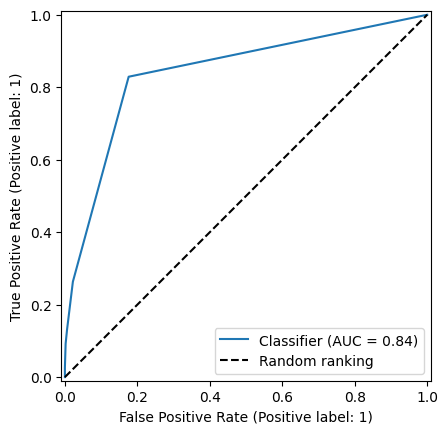

Test AUC: 0.841


In [9]:
RocCurveDisplay.from_predictions(y_test, probability)
plt.plot([0, 1], [0, 1], 'k--', label='Random ranking')
plt.legend()
plt.show()
print('Test AUC:', round(roc_auc_score(y_test, probability), 3))

**Answer**

Ja, die Kurve liegt oberhalb der Diagonalen.

- Ein AUC-Wert von 0,841 bedeutet: Bei einem zufällig ausgewählten tödlichen und einem zufällig ausgewählten nicht tödlichen Unfall weist das Modell in etwa 84 % der Fälle dem tödlichen Unfall die höhere Wahrscheinlichkeit zu (Gleichstände zählen als halb).
- Eine zufällige Rangfolge würde einen AUC-Wert von 0,5 ergeben (die Diagonale); eine perfekte Rangfolge würde einen Wert von 1,0 ergeben.
- Die Kurve weist nur wenige Ecken auf, da die Eingabegröße nur wenige verschiedene Werte annimmt (0, 1, 2, … vollständig verschüttet).
- Der AUC-Wert fasst die Rangfolge über alle Schwellenwerte hinweg zusammen. Er entspricht nicht dem Prozentsatz korrekter Klassenbezeichnungen: Bei einem Schwellenwert von 0,5 liefert das Modell zwar eine gute Rangfolge, erkennt jedoch immer noch nur 26 % der tödlichen Unfälle.

### Jupyter notebook — footer info

Include this information when submitting your notebook.

In [10]:
import platform
from datetime import datetime
print(platform.platform())
print("Python:", platform.python_version())
print("Date:", datetime.now().isoformat(timespec="seconds"))

Linux-7.0.14-linuxkit-aarch64-with-glibc2.41
Python: 3.11.17
Date: 2026-10-27T18:02:05
